# Pendulum-v1 Q-Learning (Temporal-Difference Control)

## 43008 Reinforcement Learning Assignment 2

This experiment implements tabular Q-learning to solve the Pendulum-v1 environment in Gymnasium.

Q-learning is an off-policy Temporal-Difference (TD) control algorithm that learns an action-value function through interaction with the environment.

Pendulum-v1 has continuous observation and action spaces. Therefore, state and action discretization is required to apply tabular Q-learning.

### Objectives

- Implement Q-learning using an epsilon-greedy policy.
- Discretize the continuous state and action spaces.
- Train the agent for at least 1,000 episodes.
- Visualize the training performance using learning curves.
- Evaluate the trained policy against a random agent.
- Simulate the trained agent and record a video.

## Create Output Folders

In [60]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# Main directory for Pendulum Q-learning results
base_dir = "pendulumQlearning"

# Directories for models, training logs, plots, and videos
models_dir = os.path.join(base_dir, "models")
logs_dir = os.path.join(base_dir, "logs")
plots_dir = os.path.join(base_dir, "plots")
videos_dir = os.path.join(base_dir, "videos")

# Create directories if they do not exist
for directory in [models_dir, logs_dir, plots_dir, videos_dir]:
    os.makedirs(directory, exist_ok=True)

print("Output directories created successfully!")

Output directories created successfully!


## 1. Environment Exploration

In [61]:
import gymnasium as gym
import numpy as np

# Create the Pendulum-v1 environment
env = gym.make("Pendulum-v1")

# Check the observation and action spaces
print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)

Observation Space: Box([-1. -1. -8.], [1. 1. 8.], (3,), float32)
Action Space: Box(-2.0, 2.0, (1,), float32)


In [62]:
# Reset the environment with a fixed seed for reproducibility
obs, info = env.reset(seed=42)

# Display the initial observation
print("Initial State:", obs)
print("State Shape:", obs.shape)

Initial State: [-0.14995256  0.9886932  -0.12224312]
State Shape: (3,)


In [63]:
# Apply a torque of +1.0
action = np.array([1.0], dtype=np.float32)

# Take one step in the environment
next_obs, reward, terminated, truncated, info = env.step(action)

# Display the result
print("Action:", action)
print("Next State:", next_obs)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

Action: [1.]
Next State: [-0.1878612   0.98219556  0.7692768 ]
Reward: -2.965425241287541
Terminated: False
Truncated: False


In [64]:
# Reset the environment to compare actions from the same initial state
obs, info = env.reset(seed=42)

# Apply the maximum negative torque
action = np.array([-2.0], dtype=np.float32)

# Take one step
next_obs, reward, terminated, truncated, info = env.step(action)

print("Action:", action)
print("Next State:", next_obs)
print("Reward:", reward)

# Close the environment after exploration
env.close()

Action: [-2.]
Next State: [-0.16571613  0.9861735   0.31927678]
Reward: -2.968425241430033


## 2. State Discretization
Pendulum-v1 has 3 continuous observations: cos(theta),  sin(theta), and Angular velocity.

Tabular Q-learning requires discrete state indices. 

Therefore, the pendulum angle is first calculated using atan2, and both the angle and angular velocity are divided into discrete bins.

In this experiment, 30 bins are used for the angle and 30 bins for angular velocity, resulting in 900 discrete states.


In [65]:
# Number of bins for each state variable
n_angle = 30
n_velocity = 30

# Define the internal bin boundaries for the pendulum angle
# Angle range: [-pi, pi]
angle_edges = np.linspace(-np.pi, np.pi, n_angle + 1)[1:-1]

# Define the internal bin boundaries for angular velocity
# Velocity range: [-8.0, 8.0]
velocity_edges = np.linspace(-8.0, 8.0, n_velocity + 1)[1:-1]

# Display the bin boundaries
print("Angle Edges:", angle_edges)
print("Velocity Edges:", velocity_edges)

print("Number of Angle Bins:", n_angle)
print("Number of Velocity Bins:", n_velocity)
print("Total Discrete States:", n_angle * n_velocity)

Angle Edges: [-2.93215314 -2.72271363 -2.51327412 -2.30383461 -2.0943951  -1.88495559
 -1.67551608 -1.46607657 -1.25663706 -1.04719755 -0.83775804 -0.62831853
 -0.41887902 -0.20943951  0.          0.20943951  0.41887902  0.62831853
  0.83775804  1.04719755  1.25663706  1.46607657  1.67551608  1.88495559
  2.0943951   2.30383461  2.51327412  2.72271363  2.93215314]
Velocity Edges: [-7.46666667 -6.93333333 -6.4        -5.86666667 -5.33333333 -4.8
 -4.26666667 -3.73333333 -3.2        -2.66666667 -2.13333333 -1.6
 -1.06666667 -0.53333333  0.          0.53333333  1.06666667  1.6
  2.13333333  2.66666667  3.2         3.73333333  4.26666667  4.8
  5.33333333  5.86666667  6.4         6.93333333  7.46666667]
Number of Angle Bins: 30
Number of Velocity Bins: 30
Total Discrete States: 900


### Discretize state function

In [66]:
def discretize_state(obs):
    # Convert cos(theta) and sin(theta) into the pendulum angle
    theta = np.arctan2(obs[1], obs[0])

    # Extract angular velocity from the observation
    angular_velocity = obs[2]

    # Convert continuous values into discrete bin indices
    angle_idx = np.digitize(theta, angle_edges)
    velocity_idx = np.digitize(
        angular_velocity, velocity_edges
    )

    # Return the discrete state as a tuple
    return int(angle_idx), int(velocity_idx)

### Test State Discretization

In [67]:
# Create the environment
env = gym.make("Pendulum-v1")

# Get the initial observation
obs, info = env.reset(seed=42)

# Convert the observation into a discrete state
state = discretize_state(obs)

print("Original State:", obs)
print("Discrete State:", state)

print("Angle Index:", state[0])
print("Velocity Index:", state[1])

# Verify that the indices are within the valid range
assert 0 <= state[0] < n_angle
assert 0 <= state[1] < n_velocity

print("State Discretization Test Passed!")

env.close()

Original State: [-0.14995256  0.9886932  -0.12224312]
Discrete State: (23, 14)
Angle Index: 23
Velocity Index: 14
State Discretization Test Passed!


## 3. Action Discretization and Q-table Initialization
Pendulum-v1 has a continuous action space representing torque between -2.0 and 2.0.

To apply tabular Q-learning, the torque range is divided into nine equally spaced discrete actions.

Each action is represented by an integer index. The index is mapped to a torque value before being applied to the environment.

A Q-table is initialized to store the estimated action values for every discrete state-action pair.

In [68]:
# Number of discrete torque actions
n_actions = 9

# Divide the torque range [-2.0, 2.0] into 9 actions
torque_values = np.linspace(
    -2.0, 2.0, n_actions
)

# Display the available torque values
print("Discrete Torque Values:", torque_values)
print("Number of Actions:", n_actions)

Discrete Torque Values: [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]
Number of Actions: 9


In [69]:
# Action mapping function to convert discrete action indices into torque values
def get_action(action_idx):
    # Convert the discrete action index into a torque value
    torque = torque_values[action_idx]

    # Return torque as a NumPy array with shape (1,)
    return np.array([torque], dtype=np.float32)

### Test Action Mapping

In [70]:
# Create the environment
env = gym.make("Pendulum-v1")

# Reset the environment
obs, info = env.reset(seed=42)

# Select action index 6
action_idx = 6

# Convert action index into torque
action = get_action(action_idx)

# Apply the torque to the environment
next_obs, reward, terminated, truncated, info = env.step(action)

print("Action Index:", action_idx)
print("Applied Torque:", action)
print("Next State:", next_obs)
print("Reward:", reward)

env.close()

Action Index: 6
Applied Torque: [1.]
Next State: [-0.1878612   0.98219556  0.7692768 ]
Reward: -2.965425241287541


## Initiate Q-table

In [71]:
# Initialize the Q-table with zero values
# Shape: (angle bins, velocity bins, actions)
Q = np.zeros((n_angle, n_velocity, n_actions),dtype=np.float32)

# Display Q-table information
print("Q-table Shape:", Q.shape)
print("Total Q-values:", Q.size)

Q-table Shape: (30, 30, 9)
Total Q-values: 8100


### Test Q-table Indexing

In [72]:
# Create a temporary Q-table for testing
Q_test = np.zeros(
    (n_angle, n_velocity, n_actions),
    dtype=np.float32
)

# Select a discrete state
state = (10, 12)

# Display all action values for the selected state
print("Initial Q-values:", Q_test[state])

# Assign a sample Q-value to action 6
Q_test[10, 12, 6] = 5.0

# Select the action with the highest Q-value
best_action = np.argmax(Q_test[state])

print("Updated Q-values:", Q_test[state])
print("Best Action Index:", best_action)
print("Best Torque:", get_action(best_action))

Initial Q-values: [0. 0. 0. 0. 0. 0. 0. 0. 0.]
Updated Q-values: [0. 0. 0. 0. 0. 0. 5. 0. 0.]
Best Action Index: 6
Best Torque: [1.]


In [73]:
obs, _ = env.reset(seed=0)
s = discretize_state(obs)
print(s, 0 <= s[0] < n_angle, 0 <= s[1] < n_velocity)

(19, 14) True True


## 4. Epsilon-Greedy Action Selection
An epsilon-greedy policy is used to balance exploration and exploitation during Q-learning.

With probability epsilon, the agent selects a random action to explore the environment. Otherwise, the agent selects the action with the highest estimated Q-value.

The exploration rate starts at 1.0 and gradually decreases during training. This allows the agent to explore different actions early in training and increasingly exploit its learned Q-values.

In [74]:
def epsilon_greedy_policy(Q, state, epsilon):
    # Exploration: select a random discrete action
    if np.random.random() < epsilon:
        action_idx = np.random.randint(n_actions)

    # Exploitation: select the action with the highest Q-value
    else:
        action_idx = np.argmax(Q[state])

    # Return the selected action index
    return int(action_idx)

### Test Exploration and Exploitation

In [75]:
# Create a temporary Q-table for testing
Q_test = np.zeros(
    (n_angle, n_velocity, n_actions),
    dtype=np.float32
)

# Select a sample state
state = (10, 12)

# Set action 6 as the best action
Q_test[10, 12, 6] = 5.0

# Test exploitation (epsilon = 0)
action_idx = epsilon_greedy_policy(
    Q_test, state, epsilon=0.0
)

print("Exploitation:")
print("Selected Action:", action_idx)
print("Applied Torque:", get_action(action_idx))

print("=" * 30)

# Test exploration (epsilon = 1)
print("Exploration:")

for i in range(10):

    # Select a random action
    action_idx = epsilon_greedy_policy(
        Q_test, state, epsilon=1.0
    )

    print(
        "Action Index:", action_idx,
        "| Torque:", get_action(action_idx)
    )

Exploitation:
Selected Action: 6
Applied Torque: [1.]
Exploration:
Action Index: 1 | Torque: [-1.5]
Action Index: 5 | Torque: [0.5]
Action Index: 1 | Torque: [-1.5]
Action Index: 2 | Torque: [-1.]
Action Index: 6 | Torque: [1.]
Action Index: 4 | Torque: [0.]
Action Index: 0 | Torque: [-2.]
Action Index: 1 | Torque: [-1.5]
Action Index: 7 | Torque: [1.5]
Action Index: 0 | Torque: [-2.]


## 5. Q-Learning Training
Tabular Q-learning is implemented to train the agent in Pendulum-v1.

At each step, the agent selects an action using the epsilon-greedy policy and applies the corresponding torque to the environment.

The resulting reward and next state are used to update the Q-table through the Temporal-Difference learning rule:

Q(s, a) <- Q(s, a) + alpha * [r + gamma * max Q(s', a') - Q(s, a)]

The exploration rate is gradually reduced after each episode.

Since Pendulum-v1 has no natural terminal state, Q-learning continues to bootstrap from the next state when an episode ends due to the time limit.

### Hyperparameters

In [76]:
# Number of training episodes
num_episodes = 20000

# Q-learning parameters
alpha = 0.1 # learning rate
gamma = 0.99 # discount factor

# Exploration parameters
epsilon_start = 1.0 # initial exploration rate
epsilon_min = 0.05 # minimum exploration rate
decay_episodes = 0.4 * num_episodes # episodes until epsilon reaches the minimum (40% of total episodes)
epsilon_decay = (epsilon_min / epsilon_start) ** (1 / decay_episodes)

# Random seed
seed = 42

# Episodes for saving model checkpoints
checkpoint_episodes = [1000, 6000, 20000]

# Save training configuration for reproducibility
training_config = {
    "environment": "Pendulum-v1",
    "algorithm": "Tabular Q-learning",
    "n_angle": n_angle,
    "n_velocity": n_velocity,
    "n_actions": n_actions,
    "num_episodes": num_episodes,
    "alpha": alpha,
    "gamma": gamma,
    "epsilon_start": epsilon_start,
    "epsilon_min": epsilon_min,
    "epsilon_decay": epsilon_decay,
    "seed": seed,
    "save_interval": checkpoint_episodes
}

with open(os.path.join(models_dir, "training_config.json"), "w") as f:
    json.dump(training_config, f, indent=4)

### Q-Learning Function

In [77]:
def q_learning(
    env,
    num_episodes=20000,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.999,
    seed=42,
    checkpoint_episodes=(1000, 6000, 20000)
):

    # Initialize Q-table
    Q = np.zeros(
        (n_angle, n_velocity, n_actions),
        dtype=np.float32
    )

    # Store training statistics
    training_log = []
    visited_states = set()

    # Initialize exploration rate
    epsilon = epsilon_start

    # Set random seed
    np.random.seed(seed)

    for episode in range(num_episodes):

        # Reset the environment
        obs, info = env.reset(seed=seed + episode)

        # Convert observation into discrete state
        state = discretize_state(obs)

        # Record visited state
        visited_states.add(state)

        # Initialize episode statistics
        total_reward = 0.0
        episode_steps = 0

        # Initialize termination flags
        terminated = False
        truncated = False

        while not (terminated or truncated):
            action_idx = epsilon_greedy_policy(Q, state, epsilon) # Select action using epsilon-greedy
            action = get_action(action_idx) # Convert action index into torque
            next_obs, reward, terminated, truncated, info = env.step(action) # Apply action to the environment
            next_state = discretize_state(next_obs) # Discretize the next state

            # Calculate TD target
            if terminated:
                td_target = reward
            else:
                best_next_q = np.max(Q[next_state])
                td_target = reward + gamma * best_next_q

            td_error = td_target - Q[state][action_idx] # Calculate TD error
            Q[state][action_idx] += alpha * td_error # Update Q-table

            # Update current state and statistics
            state = next_state
            total_reward += reward
            episode_steps += 1
            visited_states.add(state)

        # Reduce exploration after each episode
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

        # Store episode results
        training_log.append({
            "episode": episode + 1,
            "reward": total_reward,
            "steps": episode_steps,
            "epsilon": epsilon,
            "visited_states": len(visited_states)
        })

        # Save checkpoint and training log periodically
        if (episode + 1) in checkpoint_episodes:
            # Save the Q-table at the current training stage
            checkpoint_path = os.path.join(
                models_dir,
                f"q_table_{episode + 1}.npy"
            )
            np.save(checkpoint_path, Q)
            print(f"Checkpoint saved at episode {episode + 1}")

    # Save final trained Q-table
    np.save(os.path.join(models_dir, "q_table_final.npy"), Q)

    # Save complete training log
    df = pd.DataFrame(training_log)
    df.to_csv(os.path.join(logs_dir, "training_log.csv"), index=False)

    return Q, df, visited_states

### Training

In [78]:
# Create training environment
env = gym.make("Pendulum-v1")

# Train the Q-learning agent
Q, training_df, visited_states = q_learning(
    env=env,
    num_episodes=num_episodes,
    alpha=alpha,
    gamma=gamma,
    epsilon_start=epsilon_start,
    epsilon_min=epsilon_min,
    epsilon_decay=epsilon_decay,
    seed=seed,
    checkpoint_episodes=checkpoint_episodes
)

# Close training environment
env.close()

print("Training completed!")
print("Final Q-table shape:", Q.shape)
print("Total episodes:", len(training_df))

Checkpoint saved at episode 1000
Checkpoint saved at episode 6000
Checkpoint saved at episode 20000
Training completed!
Final Q-table shape: (30, 30, 9)
Total episodes: 20000


### Training Summary

In [79]:
# Display the training results
print("Training Completed!")
print("=" * 40)

# Total number of completed episodes
print("Total Episodes:", len(training_df))

# Average reward during the first 100 episodes
print(
    "First 100 Episodes Average:",
    round(training_df["reward"].head(100).mean(), 2)
)

# Average reward during the last 100 episodes
print(
    "Last 100 Episodes Average:",
    round(training_df["reward"].tail(100).mean(), 2)
)

# Final exploration rate
print(
    "Final Epsilon:",
    round(training_df["epsilon"].iloc[-1], 4)
)

# Number of discrete states visited during training
print("Visited States:", len(visited_states), "/", n_angle * n_velocity)

# Q-table information
print("Q-table Shape:", Q.shape)

# Total number of Q-values
print("Total Q-values:", Q.size)

# Best and worst episode rewards
print(
    "Best Episode Reward:",
    round(training_df["reward"].max(), 2)
)

print(
    "Worst Episode Reward:",
    round(training_df["reward"].min(), 2)
)

Training Completed!
Total Episodes: 20000
First 100 Episodes Average: -1233.84
Last 100 Episodes Average: -199.97
Final Epsilon: 0.05
Visited States: 833 / 900
Q-table Shape: (30, 30, 9)
Total Q-values: 8100
Best Episode Reward: -0.57
Worst Episode Reward: -1852.96


### Plot Learning Curve

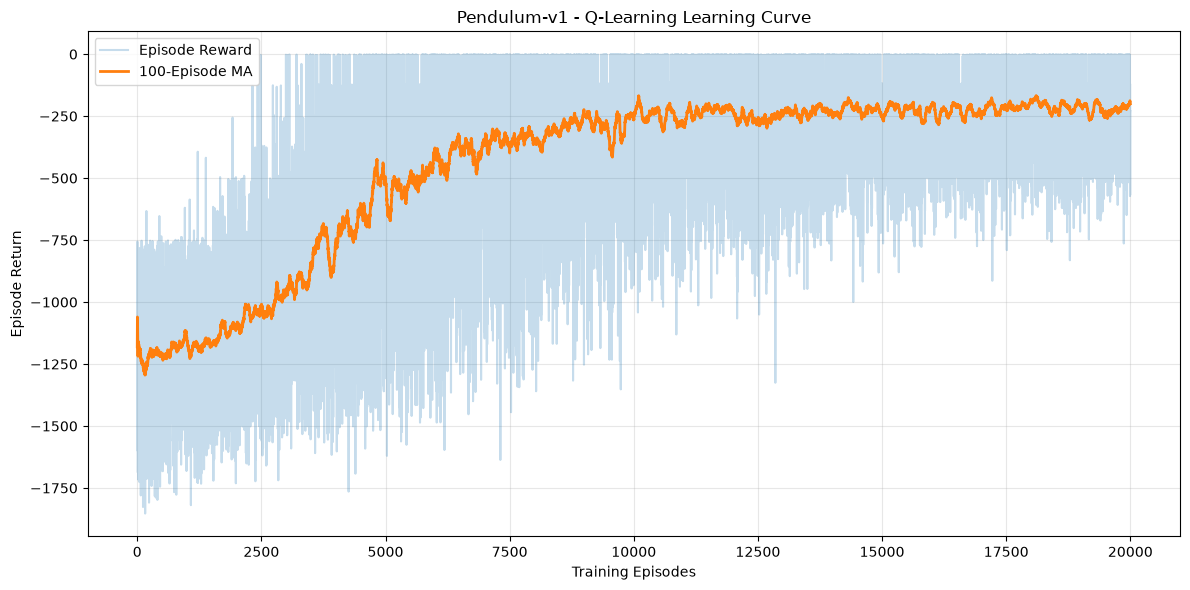

In [80]:
# Load saved training results
training_df = pd.read_csv(
    os.path.join(logs_dir, "training_log.csv")
)

# Calculate the 100-episode moving average
training_df["moving_average"] = (training_df["reward"].rolling(window=100, min_periods=1).mean())

# Create learning curve
plt.figure(figsize=(12, 6))

plt.plot(
    training_df["episode"],
    training_df["reward"],
    alpha=0.25,
    label="Episode Reward"
)

plt.plot(
    training_df["episode"],
    training_df["moving_average"],
    linewidth=2,
    label="100-Episode MA"
)

plt.xlabel("Training Episodes")
plt.ylabel("Episode Return")
plt.title("Pendulum-v1 - Q-Learning Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure for assignment report
plt.savefig(
    os.path.join(plots_dir, "learning_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Record and Save Video

In [81]:
import imageio.v2 as imageio
from IPython.display import Video, display

# Training checkpoints to visualize
video_episodes = [1000, 6000, 20000]

# Same initial state for all videos
video_seed = 123

video_results = []

for episode in video_episodes:

    # Load saved Q-table
    model_path = os.path.join(
        models_dir,
        f"q_table_{episode}.npy"
    )

    Q_loaded = np.load(model_path)

    # Create rendering environment
    env = gym.make("Pendulum-v1", render_mode="rgb_array")

    obs, info = env.reset(seed=video_seed)
    state = discretize_state(obs)

    frames = []
    total_reward = 0.0

    terminated = False
    truncated = False

    while not (terminated or truncated):

        # Capture frame
        frames.append(env.render())

        # Select best action without exploration
        action_idx = int(np.argmax(Q_loaded[state]))

        # Convert action index to torque
        action = get_action(action_idx)

        # Apply action
        next_obs, reward, terminated, truncated, info = env.step(action)

        # Update state and reward
        state = discretize_state(next_obs)
        total_reward += reward

    frames.append(env.render())
    env.close()

    # Save video for this checkpoint
    video_path = os.path.join(
        videos_dir,
        f"pendulum_episode_{episode}.mp4"
    )

    imageio.mimsave(video_path, frames, fps=30)

    video_results.append({
        "training_episodes": episode,
        "simulation_reward": total_reward
    })

    print(f"Episode {episode}: Reward = {total_reward:.2f}")

    # Display the video
    display(Video(video_path, embed=True))

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (500, 500) to (512, 512) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Episode 1000: Reward = -967.64


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (500, 500) to (512, 512) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Episode 6000: Reward = -124.38


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (500, 500) to (512, 512) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Episode 20000: Reward = -125.90
